In [140]:
#Importar librerias

from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [141]:
#Cargar dataset

df = pd.read_csv('../Data Science/datasets/HR_comma_sep.csv')
df.sample(10)

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,sales,salary
427,0.55,0.60,3,180,4,0,1,0,technical,medium
7438,0.52,0.70,4,219,3,0,0,0,hr,medium
10653,0.94,0.99,2,273,4,0,0,0,technical,low
10074,0.85,0.76,3,197,5,0,0,0,IT,medium
7708,0.99,0.54,4,239,3,0,0,0,marketing,low
4615,0.97,0.78,4,261,2,0,0,0,technical,medium
10429,0.89,0.70,3,256,4,0,0,0,support,medium
7016,0.58,0.51,2,100,2,0,0,0,product_mng,low
9344,0.86,0.73,3,159,3,0,0,0,hr,medium
13992,0.51,0.71,2,180,3,0,0,0,product_mng,low


In [142]:
# Creamos una lista llamada train_cols que contiene los nombres de las columnas
# que se utilizarán como variables predictoras (features) para entrenar el modelo.
# Estas variables representan la información que el algoritmo analizará para
# aprender patrones y realizar predicciones.
# Seleccionar únicamente las columnas relevantes ayuda a que el modelo se enfoque
# en las características que aportan información para predecir la variable objetivo.
train_cols = ['satisfaction_level', 'last_evaluation', 'number_project', 'average_montly_hours',
              'time_spend_company', 'Work_accident', 'promotion_last_5years']

# Creamos la matriz de características (X) seleccionando del DataFrame únicamente
# las columnas definidas en la lista train_cols.
# X contendrá las variables independientes o predictoras que servirán como entrada
# para el modelo de Machine Learning.
X = df[train_cols]

# Definimos la variable objetivo (target) que el modelo intentará predecir.
# La columna 'left' indica si un empleado abandonó la empresa o no.
# Esta variable se almacena en y y será utilizada durante el entrenamiento para
# que el modelo aprenda la relación entre las características de entrada y el resultado esperado.
y = df['left']

In [143]:
#Hacemos el train test split: que es la división de los datos en un conjunto de entrenamiento y un conjunto de
#prueba. Test_size = 0.3 significa que el 30% de los datos se utilizarán para la prueba y el 70% restante para el entrenamiento. y random_state = 42 asegura que la división de los datos sea reproducible, es decir, que cada vez que se ejecute el código se obtendrá la misma división de los datos.

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42)

In [144]:
#Aqui hacemos que los datos de entrenamiento y prueba tengan una media de 0 y una desviación estándar de 1. fit_transform() se utiliza para ajustar el escalador a los datos de entrenamiento y luego transformar esos datos. transform() se utiliza para transformar los datos de prueba utilizando el mismo escalador ajustado a los datos de entrenamiento.

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [145]:
# Creamos un modelo de Regresión Logística, un algoritmo de clasificación que
# estima la probabilidad de que una observación pertenezca a una determinada clase.
# El parámetro C controla la regularización del modelo.
# C = 1e10 equivale a 10.000.000.000 y representa una regularización extremadamente baja,
# lo que significa que el modelo tendrá muy pocas restricciones para ajustar los datos.
# Cuanto mayor es el valor de C, menor es la penalización sobre los coeficientes.
# Cuanto menor es C, mayor es la regularización y más simple será el modelo.
# Este valor tan alto se utiliza a veces para aproximar una regresión logística
# prácticamente sin regularización.

clf = LogisticRegression(C = 1e10)

In [146]:
# Entrenamos (fit) el modelo de Regresión Logística utilizando los datos de entrenamiento.
# Durante este proceso, el algoritmo analiza las variables de entrada (X_train)
# y sus etiquetas o valores objetivo (y_train) para aprender los patrones que
# permiten diferenciar entre las distintas clases.
# El método fit() calcula los coeficientes y el intercepto que mejor se ajustan
# a los datos, minimizando la función de coste de la Regresión Logística.
# Una vez finalizado este paso, el modelo queda entrenado y listo para realizar
# predicciones sobre nuevos datos que no ha visto anteriormente.

clf.fit(X_train, y_train)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10000000000.0
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good d

In [147]:
# Utilizamos el modelo previamente entrenado para realizar predicciones sobre
# el conjunto de datos de prueba (X_test), es decir, datos que el modelo no ha visto
# durante el entrenamiento.
# El método predict() analiza las características de cada observación y asigna
# la clase que considera más probable según los patrones aprendidos durante el entrenamiento.
# Las predicciones generadas se almacenan en la variable y_pred.
# Posteriormente, estas predicciones pueden compararse con los valores reales (y_test)
# para evaluar el rendimiento y la precisión del modelo.

y_pred = clf.predict(X_test)

In [148]:
# Importamos la función confusion_matrix desde el módulo sklearn.metrics.
# Esta función se utiliza para evaluar el rendimiento de un modelo de clasificación
# comparando las clases reales con las clases predichas por el modelo.
# La matriz de confusión permite identificar aciertos y errores de clasificación.
from sklearn.metrics import confusion_matrix

# Generamos la matriz de confusión comparando los valores reales del conjunto de prueba (y_test)
# con las predicciones realizadas por el modelo (y_pred).
# El primer parámetro corresponde a las etiquetas reales y el segundo a las etiquetas predichas.
# El resultado es una matriz que muestra cuántas observaciones fueron clasificadas correctamente
# e incorrectamente para cada clase.
confusion = confusion_matrix(y_test, y_pred)

# Mostramos la matriz de confusión en pantalla para analizar el desempeño del modelo.
# En un problema de clasificación binaria, la matriz suele interpretarse de la siguiente forma:
#
#                     Predicción
#                   0           1
# Real 0          TN          FP
# Real 1          FN          TP
#
# TN (True Negatives): negativos correctamente clasificados.
# FP (False Positives): negativos clasificados incorrectamente como positivos.
# FN (False Negatives): positivos clasificados incorrectamente como negativos.
# TP (True Positives): positivos correctamente clasificados.
print(confusion)

[[3160  268]
 [ 816  256]]


In [149]:
#Importamos la función accuracy_score desde sklearn.metrics.
# Esta métrica se utiliza para calcular la exactitud (accuracy) del modelo,
# es decir, el porcentaje de observaciones que fueron clasificadas correctamente.
# Es una de las métricas más utilizadas para evaluar modelos de clasificación.
from sklearn.metrics import accuracy_score

# Calculamos la exactitud del modelo comparando los valores reales (y_test)
# con las predicciones realizadas por el modelo (y_pred).
# El resultado será un valor entre 0 y 1:
# - 0 significa que ninguna predicción fue correcta.
# - 1 significa que todas las predicciones fueron correctas.
# Por ejemplo, un resultado de 0.85 indica que el modelo acertó el 85% de los casos.
accuracy = accuracy_score(y_test, y_pred)

# Mostramos en pantalla el valor de accuracy calculado.
# Esto nos permite conocer de forma rápida el rendimiento general del modelo
# sobre el conjunto de prueba.
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7591111111111111


In [150]:
# Utilizamos el método value_counts() para contar cuántas veces aparece cada clase
# dentro de la variable objetivo y_test.
# El parámetro normalize=True hace que los resultados se expresen como proporciones
# o porcentajes en lugar de mostrar los conteos absolutos.
# Esto permite analizar la distribución de clases en el conjunto de prueba y verificar
# si los datos están balanceados o desbalanceados.
# El resultado mostrará la frecuencia relativa de cada categoría (por ejemplo, 0 y 1)
# y la suma de todas las proporciones será igual a 1.
y_test.value_counts(normalize = True)

left
0    0.761778
1    0.238222
Name: proportion, dtype: float64

In [151]:
# Calculamos la media de la variable objetivo del conjunto de prueba (y_test).
# Como se trata de una variable binaria (por ejemplo, 0 = no abandonó la empresa
# y 1 = abandonó la empresa), la media equivale a la proporción de observaciones
# que pertenecen a la clase positiva (1).
# Este valor permite conocer rápidamente qué porcentaje de empleados abandonó la empresa
# dentro del conjunto de prueba.
# Es una forma más simple y rápida de obtener el mismo resultado que:
# y_test.value_counts(normalize=True)[1]

y_test.mean()

np.float64(0.23822222222222222)

In [152]:
1.0 - y_test.mean()

np.float64(0.7617777777777778)

In [153]:
# Calculamos la tasa de error del modelo restando el Accuracy a 1.
# Recordemos que el Accuracy representa la proporción de predicciones correctas,
# por lo que (1 - Accuracy) representa la proporción de predicciones incorrectas.
# El resultado indica el porcentaje de observaciones del conjunto de prueba
# que fueron clasificadas erróneamente por el modelo.
# Esta métrica también se conoce como Error Rate (tasa de error).
print(1 - accuracy_score(y_test, y_pred))

0.24088888888888893


In [154]:
# Importamos la función recall_score desde sklearn.metrics.
# Recall (también conocido como Sensibilidad o Tasa de Verdaderos Positivos)
# mide la capacidad del modelo para identificar correctamente los casos positivos.
# Esta métrica responde a la pregunta:
# "De todos los casos que realmente pertenecían a la clase positiva,
# ¿qué porcentaje fue detectado correctamente por el modelo?"
from sklearn.metrics import recall_score

# Calculamos el Recall comparando los valores reales (y_test)
# con las predicciones realizadas por el modelo (y_pred).
# El resultado será un valor entre 0 y 1:
# - 0 significa que el modelo no identificó ningún caso positivo correctamente.
# - 1 significa que el modelo identificó todos los casos positivos correctamente.
# Un Recall alto indica que el modelo genera pocos falsos negativos (FN).
print(recall_score(y_test, y_pred))

0.23880597014925373


In [155]:
# Extraemos el número de Verdaderos Positivos (TP) de la matriz de confusión.
# Corresponde a los casos que pertenecían realmente a la clase positiva (1)
# y que el modelo clasificó correctamente como positivos.
TP = confusion[1, 1]

# Extraemos el número de Verdaderos Negativos (TN).
# Son los casos que pertenecían realmente a la clase negativa (0)
# y que el modelo clasificó correctamente como negativos.
TN = confusion[0, 0]

# Extraemos el número de Falsos Positivos (FP).
# Son los casos que pertenecían realmente a la clase negativa (0),
# pero que el modelo clasificó incorrectamente como positivos (1).
FP = confusion[0, 1]

# Extraemos el número de Falsos Negativos (FN).
# Son los casos que pertenecían realmente a la clase positiva (1),
# pero que el modelo clasificó incorrectamente como negativos (0).
FN = confusion[1, 0]

# Calculamos la Especificidad (Specificity o True Negative Rate).
# Esta métrica mide la capacidad del modelo para identificar correctamente
# los casos negativos.
# Responde a la pregunta:
# "De todos los casos que realmente eran negativos, ¿qué porcentaje
# fue clasificado correctamente como negativo?"
#
# La fórmula es:
# Specificity = TN / (TN + FP)
#
# Un valor elevado indica que el modelo comete pocos falsos positivos.
specificity = TN / (TN + FP)

# Mostramos en pantalla el valor de la especificidad calculada.
# El resultado estará entre 0 y 1, donde los valores más cercanos a 1
# indican un mejor desempeño para detectar correctamente los casos negativos.
print(specificity)

0.9218203033838973


In [156]:
# Importamos la función f1_score desde sklearn.metrics.
# El F1-Score es una métrica que combina Precision y Recall en un único valor,
# proporcionando una medida equilibrada del rendimiento del modelo.
# Es especialmente útil cuando las clases están desbalanceadas y no es suficiente
# evaluar el modelo únicamente con Accuracy.
from sklearn.metrics import f1_score

# Calculamos el F1-Score comparando las etiquetas reales (y_test)
# con las etiquetas predichas por el modelo (y_pred).
# El resultado será un valor entre 0 y 1:
# - 0 indica un rendimiento muy deficiente.
# - 1 indica una clasificación perfecta.
# El F1-Score aumenta cuando tanto Precision como Recall son altos.
print(f1_score(y_test, y_pred))

0.3208020050125313


In [157]:
pd.Series(y_pred).unique()

array([0, 1])

In [158]:
pd.Series(y_pred).value_counts()

0    3976
1     524
Name: count, dtype: int64

In [159]:
# Utilizamos el método predict_proba() para obtener las probabilidades estimadas
# por el modelo para cada una de las clases en el conjunto de prueba.
# A diferencia de predict(), que devuelve únicamente la clase final (0 o 1),
# predict_proba() devuelve la probabilidad de pertenecer a cada clase.
# Estas probabilidades permiten analizar el nivel de confianza del modelo
# en sus predicciones.


y_pred_proba = clf.predict_proba(X_test)

In [160]:
display(y_pred_proba.shape, y_pred_proba)

(4500, 2)

array([[0.96399116, 0.03600884],
       [0.9301976 , 0.0698024 ],
       [0.81110086, 0.18889914],
       ...,
       [0.89787344, 0.10212656],
       [0.96066882, 0.03933118],
       [0.95846284, 0.04153716]], shape=(4500, 2))

In [161]:
pd.Series(y_pred).value_counts()

0    3976
1     524
Name: count, dtype: int64

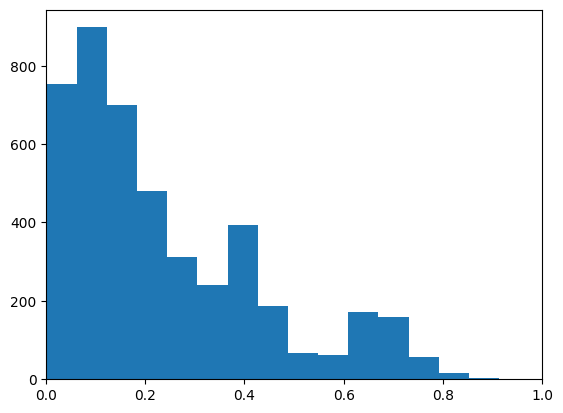

In [162]:
# Seleccionamos únicamente la segunda columna de y_pred_proba.
# Recordemos que predict_proba() devuelve una matriz con dos columnas:
# - Columna 0: probabilidad de pertenecer a la clase 0.
# - Columna 1: probabilidad de pertenecer a la clase 1.
#
# El operador [:, 1] significa:
# - :  -> seleccionar todas las filas.
# - 1  -> seleccionar la segunda columna.
#
# En este caso obtenemos la probabilidad estimada de que cada empleado
# pertenezca a la clase positiva (left = 1), es decir, que abandone la empresa.
y_probs_logit_left = y_pred_proba[:, 1]

# Creamos un histograma para visualizar la distribución de las probabilidades
# predichas por el modelo para la clase positiva.
# El parámetro bins = 15 divide el rango de probabilidades en 15 intervalos
# o barras para facilitar la visualización de la frecuencia de cada rango.
plt.hist(y_probs_logit_left, bins=15)

# Establecemos los límites del eje X entre 0 y 1.
# Esto tiene sentido porque las probabilidades siempre están comprendidas
# entre 0 (0%) y 1 (100%).
plt.xlim(0, 1)

# Mostramos el gráfico generado.
plt.show()


In [163]:
# Creamos nuevas predicciones utilizando un umbral de decisión personalizado.
# y_probs_logit_left contiene las probabilidades estimadas de pertenecer a la clase 1.
# La expresión (y_probs_logit_left > 0.3) evalúa cada probabilidad:
# - Si la probabilidad es mayor que 0.3, se asigna True.
# - Si la probabilidad es menor o igual a 0.3, se asigna False.
#
# A diferencia del umbral por defecto de 0.5 utilizado por predict(),
# aquí estamos reduciendo el umbral a 0.3 para que el modelo sea más sensible
# a la detección de la clase positiva.
#
# astype(int) convierte los valores booleanos:
# - True  -> 1
# - False -> 0
#
# El resultado es un nuevo conjunto de predicciones binarias almacenado
# en y_pred_logit.
y_pred_logit = (y_probs_logit_left > 0.3).astype(int)

# Mostramos las nuevas predicciones generadas utilizando el umbral de 0.3.
y_pred_logit

array([0, 0, 0, ..., 0, 0, 0], shape=(4500,))

In [164]:
# Mostramos la matriz de confusión obtenida utilizando las predicciones originales
# del modelo (y_pred), las cuales usan el umbral de decisión por defecto de 0.5.
# Esta matriz permite observar la cantidad de Verdaderos Positivos (TP),
# Verdaderos Negativos (TN), Falsos Positivos (FP) y Falsos Negativos (FN)
# generados por el modelo con la configuración estándar.
display(confusion_matrix(y_test, y_pred))

# Mostramos la matriz de confusión obtenida utilizando las nuevas predicciones
# (y_pred_logit), generadas con un umbral personalizado de 0.3.
# Comparar esta matriz con la anterior permite analizar cómo cambia el rendimiento
# del modelo al modificar el umbral de clasificación.
# Generalmente, al reducir el umbral aumentan las predicciones positivas,
# incrementando el Recall pero también el número de Falsos Positivos.
display(confusion_matrix(y_test, y_pred_logit))

array([[3160,  268],
       [ 816,  256]])

array([[2787,  641],
       [ 329,  743]])

In [165]:
print(accuracy_score(y_test, y_pred))
print(accuracy_score(y_test, y_pred_logit))

0.7591111111111111
0.7844444444444445


In [166]:
from sklearn.metrics import roc_curve

In [167]:
# Calculamos los puntos necesarios para construir la curva ROC.
# La función roc_curve() compara los valores reales (y_test) con las probabilidades
# predichas para la clase positiva (y_pred_proba[:, 1]).
#
# Devuelve tres arrays:
# - fpr_log: False Positive Rate (Tasa de Falsos Positivos).
# - tpr_log: True Positive Rate (Tasa de Verdaderos Positivos o Recall).
# - thr_log: umbrales utilizados para calcular cada par de valores FPR y TPR.
#
# La curva ROC permite evaluar el rendimiento del modelo para múltiples
# umbrales de clasificación en lugar de utilizar únicamente el umbral por defecto de 0.5.
fpr_log, tpr_log, thr_log = roc_curve(y_test, y_pred_proba[:, 1])

# Creamos un DataFrame con los valores calculados para la curva ROC.
# Cada fila representa un umbral diferente y contiene:
# - fpr: tasa de falsos positivos.
# - tpr: tasa de verdaderos positivos (recall).
# - thr: valor del umbral asociado.
#
# Este DataFrame facilita la exploración y el análisis de cómo cambian
# las métricas al modificar el punto de corte utilizado para clasificar.
df = pd.DataFrame(dict(fpr=fpr_log, tpr=tpr_log, thr=thr_log))

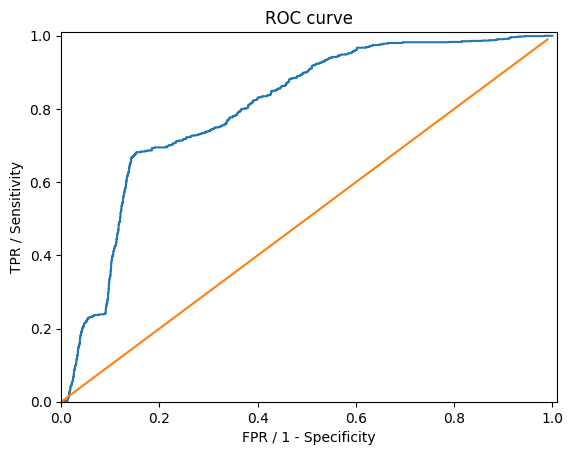

In [168]:
# Creamos un DataFrame para almacenar los valores calculados para la curva ROC.
# fpr (False Positive Rate): tasa de falsos positivos.
# tpr (True Positive Rate): tasa de verdaderos positivos o Recall.
# thr (Threshold): umbral de decisión utilizado para generar cada punto de la curva.
# Organizar estos datos en un DataFrame facilita su visualización y análisis.
df = pd.DataFrame(dict(fpr=fpr_log, tpr=tpr_log, thr=thr_log))

# Definimos los límites de los ejes del gráfico.
# El eje X y el eje Y se establecen entre 0 y 1.01 para mostrar
# completamente los valores de las tasas, ya que ambas métricas
# son proporciones comprendidas entre 0 y 1.
plt.axis([0, 1.01, 0, 1.01])

# Etiqueta del eje Y.
# TPR (True Positive Rate) también se conoce como Recall o Sensitivity.
# Indica qué proporción de los casos positivos reales
# fue detectada correctamente por el modelo.
plt.ylabel('TPR / Sensitivity')

# Etiqueta del eje X.
# FPR (False Positive Rate) representa la proporción de negativos
# que fueron clasificados incorrectamente como positivos.
# Matemáticamente:
# FPR = 1 - Specificity
plt.xlabel('FPR / 1 - Specificity')

# Añadimos un título descriptivo al gráfico.
plt.title('ROC curve')

# Dibujamos la curva ROC utilizando los valores de FPR y TPR
# calculados para distintos umbrales de clasificación.
# Cada punto de la curva representa un umbral diferente.
plt.plot(df['fpr'], df['tpr'])

# Dibujamos la diagonal de referencia.
# Esta línea representa el comportamiento de un clasificador aleatorio,
# es decir, un modelo sin capacidad predictiva.
# Una buena curva ROC debería situarse por encima de esta línea.
plt.plot(np.arange(0, 1, step=0.01),
         np.arange(0, 1, step=0.01))

# Mostramos el gráfico en pantalla.
plt.show()

In [169]:
# Importamos la función auc (Area Under the Curve) desde sklearn.metrics.
# Esta función se utiliza para calcular el área bajo la curva ROC,
# una métrica que resume en un único valor la capacidad del modelo
# para diferenciar entre las clases positiva y negativa.
from sklearn.metrics import auc

# Calculamos el AUC (Area Under the ROC Curve) utilizando los valores
# de FPR (False Positive Rate) y TPR (True Positive Rate) obtenidos
# previamente con la función roc_curve().
#
# El resultado será un valor comprendido entre 0 y 1:
# - 1.0 indica una clasificación perfecta.
# - 0.5 indica un modelo equivalente a una clasificación aleatoria.
# - Valores cercanos a 0 indican una clasificación muy deficiente.
#
# Cuanto mayor sea el AUC, mejor será la capacidad del modelo para
# distinguir entre ambas clases independientemente del umbral utilizado.
print(auc(fpr_log, tpr_log))

0.8017321139344121
